# Food Orders Dataset — Data Analysis, Cleaning, Transformation & Validation

**Role:** Data Analyst | **Source:** `food_orders.csv` | **Notebook phase:** Analytical preparation before ELT implementation

## Business objective
Prepare trustworthy food-order data for operational reporting. This notebook investigates the source structure, profiles data quality, documents cleaning decisions, creates analytical fields, answers the assignment's business questions, visualizes patterns, and validates the output.

**Important:** The ELT pipeline (batch extraction, MySQL raw loading, retrieval, transformation, validation, and analytics-database loading) will be implemented separately after this analysis is reviewed. This notebook does not connect to MySQL.

## Data handling principles
- Keep `raw_df` unchanged and perform work on a separate DataFrame.
- Remove exact duplicate rows only after measuring them.
- Do not assume repeated Order IDs are duplicates unless their records are identical.
- Keep missing financial values missing unless a defensible business rule proves they are zero.
- Use explicit labels for unknown categories; `Not Specified` does not mean `No Discount`.
- Flag questionable records rather than silently deleting them.
- Calculate financial metrics only when all required components are present.


## 0. Environment and source loading

Keep `food_orders.csv` in the same directory as this notebook, or update `DATA_PATH`. Run all cells from top to bottom.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

DATA_PATH = Path("food_orders.csv")  # Update if the CSV is stored elsewhere
RANDOM_STATE = 42

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Cannot find {DATA_PATH.resolve()}. Place food_orders.csv beside this notebook "
        "or change DATA_PATH."
    )

raw_df = pd.read_csv(DATA_PATH)
print(f"Loaded: {DATA_PATH.resolve()}")
print(f"Shape: {raw_df.shape[0]:,} rows × {raw_df.shape[1]} columns")
display(raw_df.head())


Loaded: /mnt/data/food_orders.csv
Shape: 1,010 rows × 14 columns


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
0,1,C8270,R2924,2024-02-01 01:11:52,2024-02-01 02:39:52,"1,914.00",0.00,Credit Card,5% on App,150.00,47.00,0.00,Rainy,Mobile App
1,2,C1860,R2054,2024-02-02 22:11:04,2024-02-02 22:46:04,986.00,40.00,Digital Wallet,10%,198.00,23.00,0.00,Cloudy,Mobile App
2,3,C6390,R2870,2024-01-31 05:54:35,2024-01-31 06:52:35,937.00,30.00,Cash on Delivery,15% New User,195.00,45.00,0.00,Humid,Mobile App
3,4,C6191,R2642,2024-01-16 22:52:49,2024-01-16 23:38:49,"1,463.00",NaN,Cash on Delivery,NaN,146.00,27.00,0.00,Rainy,Mobile App
4,5,C6734,R2799,2024-01-29 01:19:30,2024-01-29 02:48:30,"1,992.00",30.00,Cash on Delivery,50 off Promo,130.00,50.00,NaN,Sunny,Mobile App


## 1. Understand the dataset

One row is intended to represent one food order transaction. The fields cover order/customer/restaurant identifiers, order and delivery timestamps, order and fee amounts, payment/offer categories, weather, and order channel.

We first inspect sample records, shape, column names, data types, and statistical summaries. No cleaning is performed in this section.

In [2]:
display(raw_df.head(5))
display(raw_df.tail(5))
display(raw_df.sample(min(5, len(raw_df)), random_state=RANDOM_STATE))

print("Rows and columns:", raw_df.shape)
print("\\nColumn names:")
print(raw_df.columns.tolist())
print("\\nData types:")
display(raw_df.dtypes.rename("dtype").to_frame())

print("\\nNumeric summary:")
display(raw_df.describe(include=[np.number]).T)

print("\\nCategorical summary:")
display(raw_df.describe(include=["object"]).T)


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
0,1,C8270,R2924,2024-02-01 01:11:52,2024-02-01 02:39:52,"1,914.00",0.00,Credit Card,5% on App,150.00,47.00,0.00,Rainy,Mobile App
1,2,C1860,R2054,2024-02-02 22:11:04,2024-02-02 22:46:04,986.00,40.00,Digital Wallet,10%,198.00,23.00,0.00,Cloudy,Mobile App
2,3,C6390,R2870,2024-01-31 05:54:35,2024-01-31 06:52:35,937.00,30.00,Cash on Delivery,15% New User,195.00,45.00,0.00,Humid,Mobile App
3,4,C6191,R2642,2024-01-16 22:52:49,2024-01-16 23:38:49,"1,463.00",NaN,Cash on Delivery,NaN,146.00,27.00,0.00,Rainy,Mobile App
4,5,C6734,R2799,2024-01-29 01:19:30,2024-01-29 02:48:30,"1,992.00",30.00,Cash on Delivery,50 off Promo,130.00,50.00,NaN,Sunny,Mobile App


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
1005,208,C5736,R2750,2024-01-18 09:08:01,2024-01-18 09:49:01,NaN,50.00,Digital Wallet,50 off Promo,184.00,41.00,0.00,Rainy,Mobile App
1006,580,C8102,R2257,2024-01-03 08:46:06,2024-01-03 10:10:06,"1,045.00",40.00,Cash on Delivery,10%,137.00,13.00,0.00,Sunny,Partner App
1007,497,C9010,R2462,2024-02-04 13:07:32,2024-02-04 14:25:32,"1,125.00",0.00,Credit Card,10%,95.00,16.00,50.00,Cloudy,Partner App
1008,197,C2986,R2097,2024-01-16 13:11:39,2024-01-16 14:04:39,841.00,0.00,Cash on Delivery,15% New User,105.00,42.00,50.00,Cloudy,Mobile App
1009,133,C6915,R2074,2024-01-20 09:37:53,2024-01-20 11:05:53,"1,137.00",40.00,Credit Card,NaN,50.00,50.00,150.00,Cloudy,Mobile App


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
629,630,C1716,R2905,2024-01-13 04:16:47,2024-01-13 06:09:47,NaN,0.00,Cash on Delivery,5% on App,91.00,42.00,100.00,Rainy,Mobile App
788,789,C9659,R2778,2024-01-31 10:35:46,2024-01-31 12:07:46,714.00,40.00,Cash on Delivery,NaN,178.00,25.00,150.00,Rainy,Partner App
684,685,C7254,R2538,2024-01-07 23:31:43,2024-01-08 01:04:43,204.00,40.00,Digital Wallet,NaN,195.00,11.00,0.00,Cloudy,Mobile App
516,517,C8494,R2687,2024-01-23 05:41:17,2024-01-23 06:24:17,948.00,50.00,NaN,NaN,106.00,28.00,0.00,Sunny,Mobile App
529,530,C5268,R2697,2024-02-04 18:17:27,2024-02-04 18:51:27,"1,815.00",50.00,Cash on Delivery,15% New User,114.00,33.00,0.00,Sunny,Mobile App


Rows and columns: (1010, 14)
\nColumn names:
['Order ID', 'Customer ID', 'Restaurant ID', 'Order Date and Time', 'Delivery Date and Time', 'Order Value', 'Delivery Fee', 'Payment Method', 'Discounts and Offers', 'Commission Fee', 'Payment Processing Fee', 'Refunds/Chargebacks', 'Weather Condition', 'Order Channel']
\nData types:


,dtype
Order ID,int64
Customer ID,object
Restaurant ID,object
Order Date and Time,object
Delivery Date and Time,object
Order Value,float64
Delivery Fee,float64
Payment Method,object
Discounts and Offers,object
Commission Fee,float64


\nNumeric summary:


,count,mean,std,min,25%,50%,75%,max
Order ID,"1,010.00",499.22,288.59,1.00,248.25,498.50,748.75,"1,000.00"
Order Value,969.00,"1,055.90",529.53,104.00,600.00,"1,041.00","1,494.00","1,995.00"
Delivery Fee,960.00,28.62,16.93,0.00,20.00,30.00,40.00,50.00
Commission Fee,970.00,127.04,43.01,50.00,90.25,128.00,164.00,200.00
Payment Processing Fee,959.00,29.90,11.73,10.00,20.00,30.00,40.00,50.00
Refunds/Chargebacks,970.00,27.89,49.38,0.00,0.00,0.00,50.00,150.00


\nCategorical summary:


,count,unique,top,freq
Customer ID,1010,947,C7938,3
Restaurant ID,1010,621,R2317,6
Order Date and Time,1010,1000,2024-01-18 09:08:01,2
Delivery Date and Time,1010,1000,2024-01-18 09:49:01,2
Payment Method,960,3,Cash on Delivery,341
Discounts and Offers,768,4,10%,221
Weather Condition,1010,4,Sunny,405
Order Channel,1010,3,Mobile App,693


In [3]:
column_dictionary = pd.DataFrame([
    ("Order ID", "Unique transaction identifier", "Identifier"),
    ("Customer ID", "Customer identifier", "Identifier"),
    ("Restaurant ID", "Restaurant identifier", "Identifier"),
    ("Order Date and Time", "Timestamp when order was placed", "Datetime"),
    ("Delivery Date and Time", "Timestamp when order was delivered", "Datetime"),
    ("Order Value", "Value of food order", "Numeric / currency"),
    ("Delivery Fee", "Delivery fee charged", "Numeric / currency"),
    ("Payment Method", "Method used to pay", "Category"),
    ("Discounts and Offers", "Offer/discount applied, if recorded", "Category"),
    ("Commission Fee", "Platform commission amount", "Numeric / currency"),
    ("Payment Processing Fee", "Payment processing cost", "Numeric / currency"),
    ("Refunds/Chargebacks", "Refund or chargeback amount", "Numeric / currency"),
    ("Weather Condition", "Weather context for the order", "Category"),
    ("Order Channel", "Channel through which order was placed", "Category"),
], columns=["Column", "Business meaning", "Expected type"])
display(column_dictionary)


,Column,Business meaning,Expected type
0,Order ID,Unique transaction identifier,Identifier
1,Customer ID,Customer identifier,Identifier
2,Restaurant ID,Restaurant identifier,Identifier
3,Order Date and Time,Timestamp when order was placed,Datetime
4,Delivery Date and Time,Timestamp when order was delivered,Datetime
5,Order Value,Value of food order,Numeric / currency
6,Delivery Fee,Delivery fee charged,Numeric / currency
7,Payment Method,Method used to pay,Category
8,Discounts and Offers,"Offer/discount applied, if recorded",Category
9,Commission Fee,Platform commission amount,Numeric / currency


**Initial observation:** The dataset is order-level and contains operational, customer, restaurant, payment, and revenue-related attributes. `Order Value` supports order-value analysis; commission, delivery, processing, and refund amounts support the assignment's simplified platform-net-revenue measure; timestamps support delivery-time analysis.

## 2. Data-quality assessment

We assess missingness by count and percentage, exact duplicate rows, repeated Order IDs, data types, timestamp parseability, delivery chronology, financial ranges, and category frequencies. Repeated identifiers are investigated before any removal decision.

In [4]:
# Missing-value profile
missing_profile = pd.DataFrame({
    "missing_count": raw_df.isna().sum(),
    "missing_percent": raw_df.isna().mean().mul(100).round(2),
    "non_missing_count": raw_df.notna().sum()
}).sort_values("missing_count", ascending=False)
display(missing_profile)

# Duplicate assessment
exact_duplicate_count = int(raw_df.duplicated().sum())
repeated_order_mask = raw_df["Order ID"].duplicated(keep=False)
repeated_order_rows = raw_df.loc[repeated_order_mask].sort_values("Order ID")
print(f"Exact duplicate rows beyond first occurrence: {exact_duplicate_count}")
print(f"Rows whose Order ID is repeated: {int(repeated_order_mask.sum())}")
print(f"Unique Order IDs: {raw_df['Order ID'].nunique(dropna=True):,}")
display(repeated_order_rows)


,missing_count,missing_percent,non_missing_count
Discounts and Offers,242,23.96,768
Payment Processing Fee,51,5.05,959
Delivery Fee,50,4.95,960
Payment Method,50,4.95,960
Order Value,41,4.06,969
Commission Fee,40,3.96,970
Refunds/Chargebacks,40,3.96,970
Delivery Date and Time,0,0.00,1010
Restaurant ID,0,0.00,1010
Customer ID,0,0.00,1010


Exact duplicate rows beyond first occurrence: 10
Rows whose Order ID is repeated: 20
Unique Order IDs: 1,000


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
121,122,C7019,R2277,2024-02-05 05:55:15,2024-02-05 07:33:15,"1,438.00",0.00,Cash on Delivery,50 off Promo,51.00,NaN,0.00,Cloudy,Mobile App
1003,122,C7019,R2277,2024-02-05 05:55:15,2024-02-05 07:33:15,"1,438.00",0.00,Cash on Delivery,50 off Promo,51.00,NaN,0.00,Cloudy,Mobile App
132,133,C6915,R2074,2024-01-20 09:37:53,2024-01-20 11:05:53,"1,137.00",40.00,Credit Card,NaN,50.00,50.00,150.00,Cloudy,Mobile App
1009,133,C6915,R2074,2024-01-20 09:37:53,2024-01-20 11:05:53,"1,137.00",40.00,Credit Card,NaN,50.00,50.00,150.00,Cloudy,Mobile App
1004,156,C2853,R2286,2024-01-29 03:43:13,2024-01-29 04:32:13,"1,017.00",40.00,Cash on Delivery,5% on App,95.00,19.00,0.00,Rainy,Mobile App
155,156,C2853,R2286,2024-01-29 03:43:13,2024-01-29 04:32:13,"1,017.00",40.00,Cash on Delivery,5% on App,95.00,19.00,0.00,Rainy,Mobile App
1008,197,C2986,R2097,2024-01-16 13:11:39,2024-01-16 14:04:39,841.00,0.00,Cash on Delivery,15% New User,105.00,42.00,50.00,Cloudy,Mobile App
196,197,C2986,R2097,2024-01-16 13:11:39,2024-01-16 14:04:39,841.00,0.00,Cash on Delivery,15% New User,105.00,42.00,50.00,Cloudy,Mobile App
207,208,C5736,R2750,2024-01-18 09:08:01,2024-01-18 09:49:01,NaN,50.00,Digital Wallet,50 off Promo,184.00,41.00,0.00,Rainy,Mobile App
1005,208,C5736,R2750,2024-01-18 09:08:01,2024-01-18 09:49:01,NaN,50.00,Digital Wallet,50 off Promo,184.00,41.00,0.00,Rainy,Mobile App


In [5]:
# Parse timestamps for profiling only; raw_df remains unchanged
order_ts_profile = pd.to_datetime(raw_df["Order Date and Time"], errors="coerce")
delivery_ts_profile = pd.to_datetime(raw_df["Delivery Date and Time"], errors="coerce")
duration_profile = (delivery_ts_profile - order_ts_profile).dt.total_seconds() / 60

timestamp_profile = pd.DataFrame({
    "field": ["Order Date and Time", "Delivery Date and Time"],
    "unparseable_count": [order_ts_profile.isna().sum(), delivery_ts_profile.isna().sum()],
    "earliest": [order_ts_profile.min(), delivery_ts_profile.min()],
    "latest": [order_ts_profile.max(), delivery_ts_profile.max()]
})
display(timestamp_profile)

print("Delivery before order:", int((duration_profile < 0).sum()))
print("Zero-minute deliveries:", int((duration_profile == 0).sum()))
print("Maximum delivery duration (minutes):", duration_profile.max())
display(duration_profile.describe().to_frame("Delivery duration (minutes)"))

financial_columns = [
    "Order Value", "Delivery Fee", "Commission Fee",
    "Payment Processing Fee", "Refunds/Chargebacks"
]
financial_profile = pd.DataFrame({
    "missing": raw_df[financial_columns].isna().sum(),
    "negative_count": raw_df[financial_columns].lt(0).sum(),
    "minimum": raw_df[financial_columns].min(),
    "maximum": raw_df[financial_columns].max()
})
display(financial_profile)


,field,unparseable_count,earliest,latest
0,Order Date and Time,0,2024-01-01 02:12:47,2024-02-07 23:56:12
1,Delivery Date and Time,0,2024-01-01 03:59:47,2024-02-08 01:45:12


Delivery before order: 0
Zero-minute deliveries: 0
Maximum delivery duration (minutes): 119.0


,Delivery duration (minutes)
count,"1,010.00"
mean,73.61
std,25.97
min,30.00
25%,50.00
50%,74.00
75%,96.00
max,119.00


,missing,negative_count,minimum,maximum
Order Value,41,0,104.00,"1,995.00"
Delivery Fee,50,0,0.00,50.00
Commission Fee,40,0,50.00,200.00
Payment Processing Fee,51,0,10.00,50.00
Refunds/Chargebacks,40,0,0.00,150.00


In [6]:
categorical_columns = [
    "Payment Method", "Discounts and Offers",
    "Weather Condition", "Order Channel"
]
for col in categorical_columns:
    print(f"\\n{col} — frequency including missing")
    display(raw_df[col].value_counts(dropna=False).rename("count").to_frame())


\nPayment Method — frequency including missing


,count
Payment Method,
Cash on Delivery,341
Credit Card,323
Digital Wallet,296
NaN,50


\nDiscounts and Offers — frequency including missing


,count
Discounts and Offers,
NaN,242
10%,221
50 off Promo,194
15% New User,183
5% on App,170


\nWeather Condition — frequency including missing


,count
Weather Condition,
Sunny,405
Cloudy,252
Rainy,202
Humid,151


\nOrder Channel — frequency including missing


,count
Order Channel,
Mobile App,693
Partner App,165
Website,152


### Data-quality findings from the supplied CSV

The dataset has **1,010 rows and 14 columns**. Initial profiling identifies:
1. **Exact duplicate transactions:** 10 rows are exact duplicates beyond their first occurrence. If counted twice, they inflate order counts and financial totals.
2. **Repeated Order IDs:** 20 rows belong to repeated IDs (10 IDs appearing twice). These need comparison at the full-row level; the repeated IDs in this file correspond to exact duplicate pairs, but the cleaning step still checks for conflicting records after exact duplicates are removed.
3. **Financial/category missingness:** Order Value, fee fields, refunds, payment method, and offers contain missing values. Treating missing money as zero could bias revenue and order-value measures.
4. **Offer missingness:** A blank offer field means the offer status is unknown/not recorded, not necessarily that no discount was applied.
5. **Timestamp and delivery checks:** timestamps are parsed and delivery durations are tested for impossible chronology before being accepted.

The exact values and counts are displayed by the executable profiling cells above; the cleaning and validation sections below repeat key checks against the working data.

## 3. Cleaning rules — decide before changing data

| Data-quality issue | Handling rule | Reason / business assumption |
|---|---|---|
| Exact duplicate rows | Remove subsequent exact copies; retain one copy | Exact same transaction content should not inflate counts or totals |
| Repeated Order ID with conflicting attributes | Retain for investigation and flag; do not arbitrarily select one | Could represent a source-system conflict; needs business confirmation |
| Missing Order Value | Retain as missing; exclude only from order-value metrics | No defensible value can be inferred from the other columns |
| Missing Delivery Fee / Commission / Processing Fee / Refund | Retain as missing; revenue formula remains missing if any component is missing | Missing amount is not proof of zero |
| Missing Payment Method | Replace missing category with `Unknown` in the analytical copy | Allows category counts while preserving the fact that method is unknown |
| Missing Discounts and Offers | Replace with `Not Specified` | Does not incorrectly assert that no offer was applied |
| Invalid timestamps | Convert parse failures to `NaT`; flag affected records | Invalid chronology cannot support delivery-time calculations |
| Negative delivery duration | Flag as invalid; do not classify as valid delivery time | Delivery cannot occur before order placement |
| Suspiciously long duration | Flag for review using an explicit threshold; retain unless confirmed erroneous | Outliers may be genuine and should not be silently deleted |

**Outlier review threshold:** for this exploratory assignment, durations above 180 minutes are flagged for investigation. This is a review rule, not proof that the record is wrong.

## 4. Clean the dataset

Create `work_df` from `raw_df`. Exact duplicates are removed. Then check whether any repeated Order IDs remain and whether their rows conflict. Datetimes and financial fields are explicitly converted. Missing financial values are intentionally retained.

In [7]:
work_df = raw_df.copy(deep=True)
original_row_count = len(work_df)

# Remove exact duplicate rows only
work_df = work_df.drop_duplicates(keep="first").copy()
rows_removed_exact_duplicates = original_row_count - len(work_df)

# Explicit type conversion
datetime_columns = ["Order Date and Time", "Delivery Date and Time"]
for col in datetime_columns:
    work_df[col] = pd.to_datetime(work_df[col], errors="coerce")

for col in financial_columns:
    work_df[col] = pd.to_numeric(work_df[col], errors="coerce")

# Fill category gaps with transparent labels, not business assumptions
work_df["Payment Method"] = work_df["Payment Method"].fillna("Unknown")
work_df["Discounts and Offers"] = work_df["Discounts and Offers"].fillna("Not Specified")

# Check repeated IDs after exact-duplicate removal
remaining_repeated_mask = work_df["Order ID"].duplicated(keep=False)
remaining_repeated_ids = work_df.loc[remaining_repeated_mask].sort_values("Order ID")
print(f"Original rows: {original_row_count:,}")
print(f"Exact duplicate rows removed: {rows_removed_exact_duplicates:,}")
print(f"Rows after exact-deduplication: {len(work_df):,}")
print(f"Rows still involved in repeated Order IDs: {len(remaining_repeated_ids):,}")
display(remaining_repeated_ids.head(20))


Original rows: 1,010
Exact duplicate rows removed: 10
Rows after exact-deduplication: 1,000
Rows still involved in repeated Order IDs: 0


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel


In [8]:
# Flag conflicting Order IDs if repeated IDs remain
if len(remaining_repeated_ids):
    id_conflict_summary = (
        remaining_repeated_ids.groupby("Order ID", dropna=False)
        .nunique(dropna=False)
        .max(axis=1)
        .rename("maximum_distinct_values_in_any_column")
        .to_frame()
    )
    display(id_conflict_summary)
else:
    print("No repeated Order IDs remain after exact duplicate removal.")

print("Cleaned preview:")
display(work_df.head())
print("Data types:")
display(work_df.dtypes.rename("dtype").to_frame())

print("Missing values after cleaning:")
display(work_df.isna().sum().rename("missing_count").to_frame())


No repeated Order IDs remain after exact duplicate removal.
Cleaned preview:


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
0,1,C8270,R2924,2024-02-01 01:11:52,2024-02-01 02:39:52,"1,914.00",0.00,Credit Card,5% on App,150.00,47.00,0.00,Rainy,Mobile App
1,2,C1860,R2054,2024-02-02 22:11:04,2024-02-02 22:46:04,986.00,40.00,Digital Wallet,10%,198.00,23.00,0.00,Cloudy,Mobile App
2,3,C6390,R2870,2024-01-31 05:54:35,2024-01-31 06:52:35,937.00,30.00,Cash on Delivery,15% New User,195.00,45.00,0.00,Humid,Mobile App
3,4,C6191,R2642,2024-01-16 22:52:49,2024-01-16 23:38:49,"1,463.00",NaN,Cash on Delivery,Not Specified,146.00,27.00,0.00,Rainy,Mobile App
4,5,C6734,R2799,2024-01-29 01:19:30,2024-01-29 02:48:30,"1,992.00",30.00,Cash on Delivery,50 off Promo,130.00,50.00,NaN,Sunny,Mobile App


Data types:


,dtype
Order ID,int64
Customer ID,object
Restaurant ID,object
Order Date and Time,datetime64[ns]
Delivery Date and Time,datetime64[ns]
Order Value,float64
Delivery Fee,float64
Payment Method,object
Discounts and Offers,object
Commission Fee,float64


Missing values after cleaning:


,missing_count
Order ID,0
Customer ID,0
Restaurant ID,0
Order Date and Time,0
Delivery Date and Time,0
Order Value,40
Delivery Fee,50
Payment Method,0
Discounts and Offers,0
Commission Fee,40


**Cleaning interpretation:** Exact duplicate rows are removed because every field matches. If a repeated Order ID with differing attributes remains, the notebook deliberately retains it for investigation instead of choosing an arbitrary row. Financial nulls remain null; category nulls are represented by explicit unknown labels.

## 5. Transform data and derive analytical columns

Create:
- `Delivery_Time_Minutes`: delivery timestamp minus order timestamp, in minutes.
- `Order_Date`: date portion of order timestamp.
- `Order_Hour`: hour of order placement.
- `Platform_Net_Revenue`: Commission Fee + Delivery Fee − Payment Processing Fee − Refunds/Chargebacks.

The revenue metric is calculated only when **all four** inputs exist. It is a simplified assignment metric, not a complete accounting definition.

In [9]:
# Derived temporal fields
work_df["Delivery_Time_Minutes"] = (
    work_df["Delivery Date and Time"] - work_df["Order Date and Time"]
).dt.total_seconds() / 60

work_df["Order_Date"] = work_df["Order Date and Time"].dt.date
work_df["Order_Hour"] = work_df["Order Date and Time"].dt.hour

revenue_components = [
    "Commission Fee", "Delivery Fee",
    "Payment Processing Fee", "Refunds/Chargebacks"
]
revenue_inputs_complete = work_df[revenue_components].notna().all(axis=1)
work_df["Platform_Net_Revenue"] = np.where(
    revenue_inputs_complete,
    work_df["Commission Fee"] + work_df["Delivery Fee"]
    - work_df["Payment Processing Fee"] - work_df["Refunds/Chargebacks"],
    np.nan
)

# Quality flags: keep records, but make their status explicit
work_df["Invalid_Timestamp_Flag"] = (
    work_df["Order Date and Time"].isna() | work_df["Delivery Date and Time"].isna()
)
work_df["Negative_Delivery_Time_Flag"] = work_df["Delivery_Time_Minutes"].lt(0)
work_df["Long_Delivery_Time_Flag"] = work_df["Delivery_Time_Minutes"].gt(180)
work_df["Valid_Delivery_Time_Flag"] = (
    work_df["Delivery_Time_Minutes"].notna()
    & work_df["Delivery_Time_Minutes"].ge(0)
    & ~work_df["Long_Delivery_Time_Flag"]
)

display(work_df[[
    "Order ID", "Order Date and Time", "Delivery Date and Time",
    "Delivery_Time_Minutes", "Order_Date", "Order_Hour",
    "Platform_Net_Revenue", "Valid_Delivery_Time_Flag"
]].head(10))


,Order ID,Order Date and Time,Delivery Date and Time,Delivery_Time_Minutes,Order_Date,Order_Hour,Platform_Net_Revenue,Valid_Delivery_Time_Flag
0,1,2024-02-01 01:11:52,2024-02-01 02:39:52,88.00,2024-02-01,1,103.00,True
1,2,2024-02-02 22:11:04,2024-02-02 22:46:04,35.00,2024-02-02,22,215.00,True
2,3,2024-01-31 05:54:35,2024-01-31 06:52:35,58.00,2024-01-31,5,180.00,True
3,4,2024-01-16 22:52:49,2024-01-16 23:38:49,46.00,2024-01-16,22,NaN,True
4,5,2024-01-29 01:19:30,2024-01-29 02:48:30,89.00,2024-01-29,1,NaN,True
5,6,2024-01-25 04:36:52,2024-01-25 05:27:52,51.00,2024-01-25,4,-65.00,True
6,7,2024-01-12 23:55:48,2024-01-13 00:48:48,53.00,2024-01-12,23,112.00,True
7,8,2024-01-26 22:46:24,2024-01-27 00:36:24,110.00,2024-01-26,22,36.00,True
8,9,2024-01-02 18:29:59,2024-01-02 20:23:59,114.00,2024-01-02,18,108.00,True
9,10,2024-01-05 00:50:19,2024-01-05 02:10:19,80.00,2024-01-05,0,219.00,True


In [10]:
delivery_flag_summary = pd.Series({
    "Missing/unparseable timestamp rows": int(work_df["Invalid_Timestamp_Flag"].sum()),
    "Missing delivery duration rows": int(work_df["Delivery_Time_Minutes"].isna().sum()),
    "Negative delivery duration rows": int(work_df["Negative_Delivery_Time_Flag"].sum()),
    "Over 180-minute review flags": int(work_df["Long_Delivery_Time_Flag"].sum()),
    "Valid delivery duration rows": int(work_df["Valid_Delivery_Time_Flag"].sum()),
    "Rows with complete revenue inputs": int(revenue_inputs_complete.sum()),
    "Rows missing at least one revenue input": int((~revenue_inputs_complete).sum())
})
display(delivery_flag_summary.to_frame("record_count"))


,record_count
Missing/unparseable timestamp rows,0
Missing delivery duration rows,0
Negative delivery duration rows,0
Over 180-minute review flags,0
Valid delivery duration rows,1000
Rows with complete revenue inputs,828
Rows missing at least one revenue input,172


**Interpretation guide:** A delivery duration is unavailable when either timestamp is missing or cannot be parsed. Negative durations are impossible under the stated business process and must be flagged. Long durations are review candidates, not automatically rejected. Missing revenue inputs prevent a complete calculation; replacing them with zero would create unsupported revenue estimates.

## 6. Business questions

All answers below are computed from the cleaned analytical DataFrame. Financial metrics explicitly state their population. Category rankings exclude unknown payment methods when answering the question about known methods.

In [11]:
# 1. Original and cleaned record counts
record_counts = pd.DataFrame({
    "metric": ["Original source rows", "Rows after exact duplicate removal",
               "Exact duplicate rows removed", "Rows with valid Order Value",
               "Rows with complete Platform_Net_Revenue inputs"],
    "count": [
        len(raw_df), len(work_df), rows_removed_exact_duplicates,
        int(work_df["Order Value"].notna().sum()),
        int(work_df["Platform_Net_Revenue"].notna().sum())
    ]
})
display(record_counts)

# 2. Total, mean, median order value — valid values only
valid_order_values = work_df["Order Value"].dropna()
order_value_summary = pd.DataFrame({
    "metric": ["Total Order Value", "Mean Order Value", "Median Order Value"],
    "value": [
        valid_order_values.sum(),
        valid_order_values.mean(),
        valid_order_values.median()
    ]
})
display(order_value_summary)
print(f"Order-value population: {len(valid_order_values):,} valid records out of {len(work_df):,}.")


,metric,count
0,Original source rows,1010
1,Rows after exact duplicate removal,1000
2,Exact duplicate rows removed,10
3,Rows with valid Order Value,960
4,Rows with complete Platform_Net_Revenue inputs,828


,metric,value
0,Total Order Value,"1,013,415.00"
1,Mean Order Value,"1,055.64"
2,Median Order Value,"1,040.00"


Order-value population: 960 valid records out of 1,000.


In [12]:
# 3–5. Most frequent known payment method, order channel, and weather condition
known_payment_counts = work_df.loc[
    work_df["Payment Method"].ne("Unknown"), "Payment Method"
].value_counts()
channel_counts = work_df["Order Channel"].value_counts(dropna=False)
weather_counts = work_df["Weather Condition"].value_counts(dropna=False)

print("Payment method counts (known methods only):")
display(known_payment_counts.to_frame("orders"))
print("Order channel counts:")
display(channel_counts.to_frame("orders"))
print("Weather condition counts:")
display(weather_counts.to_frame("orders"))

def top_category(series):
    return series.index[0] if len(series) else "No data"

print("Most common known payment method:", top_category(known_payment_counts))
print("Most common order channel:", top_category(channel_counts))
print("Most common weather condition:", top_category(weather_counts))


Payment method counts (known methods only):


,orders
Payment Method,
Cash on Delivery,336
Credit Card,320
Digital Wallet,294


Order channel counts:


,orders
Order Channel,
Mobile App,686
Partner App,162
Website,152


Weather condition counts:


,orders
Weather Condition,
Sunny,402
Cloudy,247
Rainy,200
Humid,151


Most common known payment method: Cash on Delivery
Most common order channel: Mobile App
Most common weather condition: Sunny


In [13]:
# 6. Mean and median delivery time among valid delivery durations
valid_delivery = work_df.loc[
    work_df["Valid_Delivery_Time_Flag"], "Delivery_Time_Minutes"
].dropna()
delivery_summary = pd.DataFrame({
    "metric": ["Mean delivery time (minutes)", "Median delivery time (minutes)"],
    "value": [valid_delivery.mean(), valid_delivery.median()]
})
display(delivery_summary)
print(f"Delivery-time population: {len(valid_delivery):,} valid records.")


,metric,value
0,Mean delivery time (minutes),73.58
1,Median delivery time (minutes),74.00


Delivery-time population: 1,000 valid records.


In [14]:
# 7. Five restaurants with the highest order counts
restaurant_order_counts = (
    work_df.groupby("Restaurant ID", dropna=False)
    .size()
    .sort_values(ascending=False)
    .head(5)
    .rename("order_count")
    .reset_index()
)
display(restaurant_order_counts)


,Restaurant ID,order_count
0,R2317,6
1,R2523,5
2,R2726,5
3,R2083,5
4,R2016,5


In [15]:
# 8. Total simplified Platform Net Revenue
valid_revenue = work_df["Platform_Net_Revenue"].dropna()
revenue_result = pd.DataFrame({
    "metric": ["Total Platform_Net_Revenue", "Records included", "Records excluded due to missing component"],
    "value": [
        valid_revenue.sum(),
        len(valid_revenue),
        int(work_df["Platform_Net_Revenue"].isna().sum())
    ]
})
display(revenue_result)


,metric,value
0,Total Platform_Net_Revenue,"80,877.00"
1,Records included,828.00
2,Records excluded due to missing component,172.00


### Business interpretation

Use the calculated tables above to write a short interpretation in your own words. In particular:
- State the order-value total/average/median and the number of records used.
- Identify the leading known payment method, channel, and weather category.
- Compare mean and median delivery time; a large difference can indicate skew or unusually long deliveries.
- Treat the top-five restaurant list as order volume, not restaurant quality or profitability.
- State that total platform net revenue covers only rows with all four revenue components available; it may not represent the full business total.

## 7. Visual analysis

The following charts show order channel, known payment method, delivery time by weather, and daily order volume. Charts are descriptive; they do not establish causation.

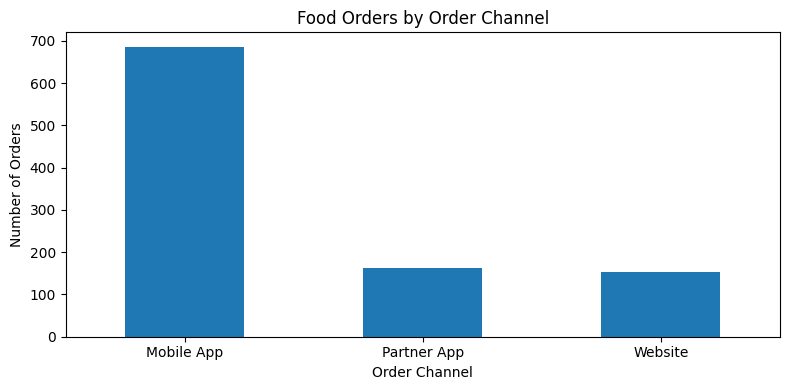

In [16]:
# Chart 1 — Orders by order channel
channel_plot = work_df["Order Channel"].value_counts()
ax = channel_plot.plot(kind="bar", figsize=(8, 4))
ax.set_title("Food Orders by Order Channel")
ax.set_xlabel("Order Channel")
ax.set_ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


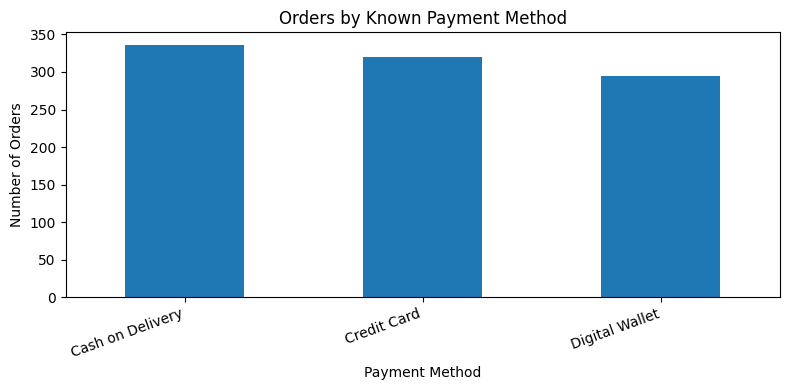

In [17]:
# Chart 2 — Orders by known payment method
payment_plot = work_df.loc[
    work_df["Payment Method"].ne("Unknown"), "Payment Method"
].value_counts()
ax = payment_plot.plot(kind="bar", figsize=(8, 4))
ax.set_title("Orders by Known Payment Method")
ax.set_xlabel("Payment Method")
ax.set_ylabel("Number of Orders")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


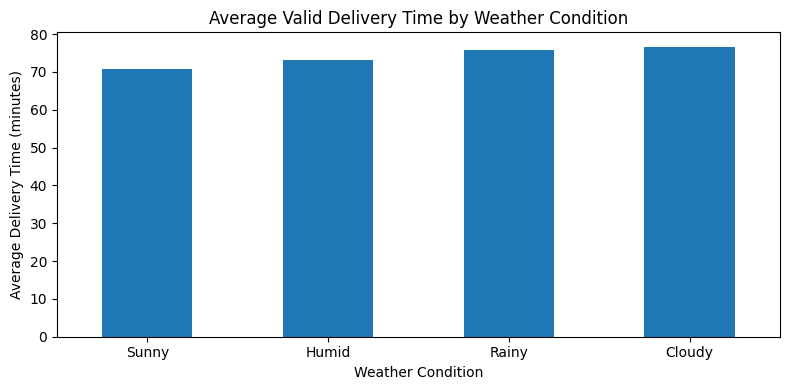

In [18]:
# Chart 3 — Average delivery time by weather condition
weather_delivery = (
    work_df.loc[work_df["Valid_Delivery_Time_Flag"]]
    .groupby("Weather Condition")["Delivery_Time_Minutes"]
    .mean()
    .sort_values()
)
ax = weather_delivery.plot(kind="bar", figsize=(8, 4))
ax.set_title("Average Valid Delivery Time by Weather Condition")
ax.set_xlabel("Weather Condition")
ax.set_ylabel("Average Delivery Time (minutes)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


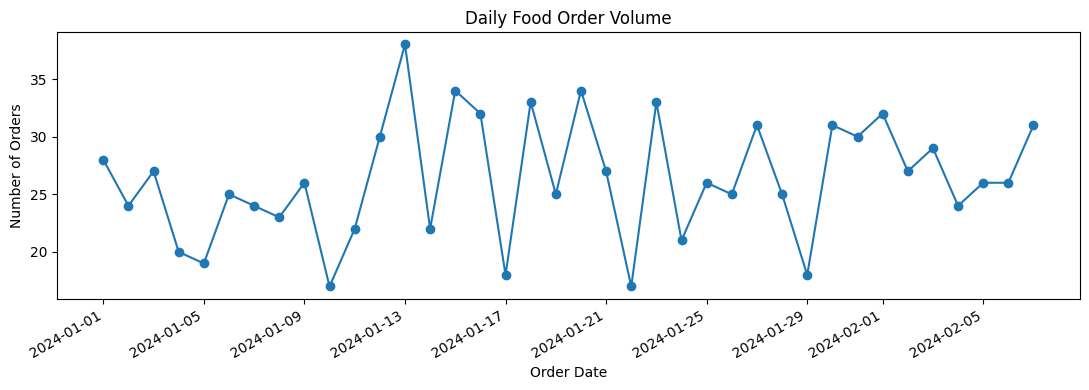

In [19]:
# Chart 4 — Daily order count
daily_orders = (
    work_df.dropna(subset=["Order_Date"])
    .groupby("Order_Date")
    .size()
    .sort_index()
)
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(pd.to_datetime(daily_orders.index), daily_orders.values, marker="o")
ax.set_title("Daily Food Order Volume")
ax.set_xlabel("Order Date")
ax.set_ylabel("Number of Orders")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


**Chart notes:** Compare the relative bar heights to identify the most-used channels and payment methods. The weather chart compares observed average delivery times by recorded weather category; differences may be associated with many other factors and should not be interpreted as weather causing delays. The daily chart helps identify changes in order volume over the observed period.

## 8. Validation checks

Validation is about demonstrating that the output follows the documented rules, not forcing every missing-value count to zero. The checks below report expected columns, data types, duplicates, repeated IDs, delivery-time validity, formula correctness, missingness changes, and row accounting.

In [20]:
expected_original_columns = raw_df.columns.tolist()
expected_derived_columns = [
    "Delivery_Time_Minutes", "Order_Date", "Order_Hour",
    "Platform_Net_Revenue", "Invalid_Timestamp_Flag",
    "Negative_Delivery_Time_Flag", "Long_Delivery_Time_Flag",
    "Valid_Delivery_Time_Flag"
]
missing_expected = [c for c in expected_original_columns + expected_derived_columns if c not in work_df.columns]
print("Expected columns missing:", missing_expected)
print("Exact duplicate rows remaining:", int(work_df.duplicated().sum()))
print("Repeated Order IDs remaining:", int(work_df["Order ID"].duplicated(keep=False).sum()))
print("Datetime dtypes:", work_df[datetime_columns].dtypes.astype(str).to_dict())
print("Financial dtypes:", work_df[financial_columns + ["Platform_Net_Revenue"]].dtypes.astype(str).to_dict())

valid_duration_values = work_df.loc[work_df["Valid_Delivery_Time_Flag"], "Delivery_Time_Minutes"]
print("Negative durations in valid population:", int(valid_duration_values.lt(0).sum()))
print("All valid delivery durations are non-negative:", bool(valid_duration_values.ge(0).all()))


Expected columns missing: []
Exact duplicate rows remaining: 0
Repeated Order IDs remaining: 0
Datetime dtypes: {'Order Date and Time': 'datetime64[ns]', 'Delivery Date and Time': 'datetime64[ns]'}
Financial dtypes: {'Order Value': 'float64', 'Delivery Fee': 'float64', 'Commission Fee': 'float64', 'Payment Processing Fee': 'float64', 'Refunds/Chargebacks': 'float64', 'Platform_Net_Revenue': 'float64'}
Negative durations in valid population: 0
All valid delivery durations are non-negative: True


In [21]:
# Verify duration and revenue formulas on a sample of eligible records
duration_check = work_df.dropna(subset=[
    "Order Date and Time", "Delivery Date and Time", "Delivery_Time_Minutes"
]).head(5).copy()
duration_check["recalculated_duration"] = (
    duration_check["Delivery Date and Time"] - duration_check["Order Date and Time"]
).dt.total_seconds() / 60
duration_check["duration_matches"] = np.isclose(
    duration_check["Delivery_Time_Minutes"], duration_check["recalculated_duration"]
)
display(duration_check[[
    "Order ID", "Delivery_Time_Minutes", "recalculated_duration", "duration_matches"
]])

revenue_check = work_df.loc[revenue_inputs_complete].head(5).copy()
revenue_check["recalculated_revenue"] = (
    revenue_check["Commission Fee"] + revenue_check["Delivery Fee"]
    - revenue_check["Payment Processing Fee"] - revenue_check["Refunds/Chargebacks"]
)
revenue_check["revenue_matches"] = np.isclose(
    revenue_check["Platform_Net_Revenue"], revenue_check["recalculated_revenue"]
)
display(revenue_check[[
    "Order ID", "Platform_Net_Revenue", "recalculated_revenue", "revenue_matches"
]])


,Order ID,Delivery_Time_Minutes,recalculated_duration,duration_matches
0,1,88.00,88.00,True
1,2,35.00,35.00,True
2,3,58.00,58.00,True
3,4,46.00,46.00,True
4,5,89.00,89.00,True


,Order ID,Platform_Net_Revenue,recalculated_revenue,revenue_matches
0,1,103.00,103.00,True
1,2,215.00,215.00,True
2,3,180.00,180.00,True
5,6,-65.00,-65.00,True
6,7,112.00,112.00,True


In [22]:
# Missing-value comparison: original vs cleaned analytical data
missing_comparison = pd.DataFrame({
    "before_cleaning": raw_df.isna().sum(),
    "after_cleaning": work_df[raw_df.columns].isna().sum()
})
missing_comparison["change"] = (
    missing_comparison["after_cleaning"] - missing_comparison["before_cleaning"]
)
display(missing_comparison)

# Row accounting
row_accounting = pd.DataFrame({
    "stage": [
        "Original CSV",
        "After exact duplicate removal",
        "Rows with valid Order Value",
        "Rows with valid delivery duration",
        "Rows with complete revenue components"
    ],
    "records": [
        len(raw_df), len(work_df),
        int(work_df["Order Value"].notna().sum()),
        int(work_df["Valid_Delivery_Time_Flag"].sum()),
        int(work_df["Platform_Net_Revenue"].notna().sum())
    ]
})
display(row_accounting)


,before_cleaning,after_cleaning,change
Order ID,0,0,0
Customer ID,0,0,0
Restaurant ID,0,0,0
Order Date and Time,0,0,0
Delivery Date and Time,0,0,0
Order Value,41,40,-1
Delivery Fee,50,50,0
Payment Method,50,0,-50
Discounts and Offers,242,0,-242
Commission Fee,40,40,0


,stage,records
0,Original CSV,1010
1,After exact duplicate removal,1000
2,Rows with valid Order Value,960
3,Rows with valid delivery duration,1000
4,Rows with complete revenue components,828


In [23]:
# Programmatic validation summary
validation_checks = {
    "All expected original and derived columns exist": len(missing_expected) == 0,
    "No exact duplicate rows remain": work_df.duplicated().sum() == 0,
    "Datetime columns use datetime dtype": all(
        pd.api.types.is_datetime64_any_dtype(work_df[c]) for c in datetime_columns
    ),
    "Financial columns are numeric": all(
        pd.api.types.is_numeric_dtype(work_df[c])
        for c in financial_columns + ["Platform_Net_Revenue"]
    ),
    "Valid delivery durations are non-negative": bool(valid_duration_values.ge(0).all()),
    "Sample duration calculations match": bool(duration_check["duration_matches"].all()),
    "Sample revenue calculations match": bool(revenue_check["revenue_matches"].all()),
}
validation_report = pd.DataFrame(
    [{"check": k, "passed": bool(v)} for k, v in validation_checks.items()]
)
display(validation_report)
print("Overall validation:", "PASS" if validation_report["passed"].all() else "REVIEW REQUIRED")


,check,passed
0,All expected original and derived columns exist,True
1,No exact duplicate rows remain,True
2,Datetime columns use datetime dtype,True
3,Financial columns are numeric,True
4,Valid delivery durations are non-negative,True
5,Sample duration calculations match,True
6,Sample revenue calculations match,True


Overall validation: PASS


## 9. Final analytical summary and limitations

Before submission, complete the written interpretation based on the outputs above.

### What this notebook establishes
- The source dataset's structure, field meanings, and data types.
- The extent and location of missing values and exact duplicates.
- Whether repeated identifiers remain after exact duplicate removal.
- Defensible cleaning rules that preserve unknown financial amounts.
- Derived delivery-time and simplified platform-net-revenue fields.
- Descriptive business metrics and visual patterns.
- Validation evidence for key transformations.

### Limitations to disclose
- Missing order values and fee/refund components mean financial totals may cover only a subset of orders.
- `Unknown` payment method and `Not Specified` offer are reporting labels, not recovered source values.
- The revenue calculation is the simplified formula specified in the assignment, not an accounting statement.
- Restaurant IDs are identifiers; the dataset does not provide restaurant names.
- A duration threshold is a review flag and does not prove a record is erroneous.
- This dataset is a finite extract; conclusions describe these records, not necessarily the company's full business.

## 10. Save the analytical output

Save the cleaned analytical dataset and validation report. These artifacts will support the next phase: implementing the batch-based ELT pipeline with MySQL. The original CSV and `raw_df` remain unchanged.

In [24]:
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

cleaned_output_path = OUTPUT_DIR / "food_orders_cleaned_analysis.csv"
validation_output_path = OUTPUT_DIR / "food_orders_validation_report.csv"
missing_output_path = OUTPUT_DIR / "food_orders_missing_value_comparison.csv"

work_df.to_csv(cleaned_output_path, index=False)
validation_report.to_csv(validation_output_path, index=False)
missing_comparison.to_csv(missing_output_path)

print("Saved analytical outputs:")
print(cleaned_output_path.resolve())
print(validation_output_path.resolve())
print(missing_output_path.resolve())


Saved analytical outputs:
/mnt/data/outputs/food_orders_cleaned_analysis.csv
/mnt/data/outputs/food_orders_validation_report.csv
/mnt/data/outputs/food_orders_missing_value_comparison.csv


## 11. Handoff to the ELT pipeline phase

Once this notebook has been run and reviewed, the next implementation should follow the assignment's architecture:

1. Extract `food_orders.csv` in batches of 100 without cleaning.
2. Load every original row, including nulls and duplicates, into `food_orders_raw_db.raw_food_orders`.
3. Retrieve raw rows from MySQL in batches.
4. Transform using the rules established here, including cross-batch duplicate handling.
5. Validate transformed records and capture rejected records with reasons.
6. Load accepted records into `food_orders_analytics_db.cleaned_food_orders`.
7. Generate SQL business analysis and a final pipeline execution report.

**Important ELT design point:** duplicate detection cannot be limited to an individual 100-row batch. The pipeline must compare records across batch boundaries (for example, by a stable row fingerprint and/or transaction key plus conflict checks).